# Predictive modeling of customer bookings

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
path = '/content/drive/MyDrive/PRAC/british airways/customer_booking.csv'
df = pd.read_csv(path, encoding='ISO-8859-1')

In [4]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

Data Disctionary:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

In [6]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [7]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [8]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [9]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


# Cleaning

In [11]:
import numpy as np

In [12]:
missing_val = df.isnull().sum()
missing_val

,0
num_passengers,0
sales_channel,0
trip_type,0
purchase_lead,0
length_of_stay,0
flight_hour,0
flight_day,0
route,0
booking_origin,0
wants_extra_baggage,0


In [13]:
num_duplicates = df.duplicated().sum()
num_duplicates

np.int64(719)

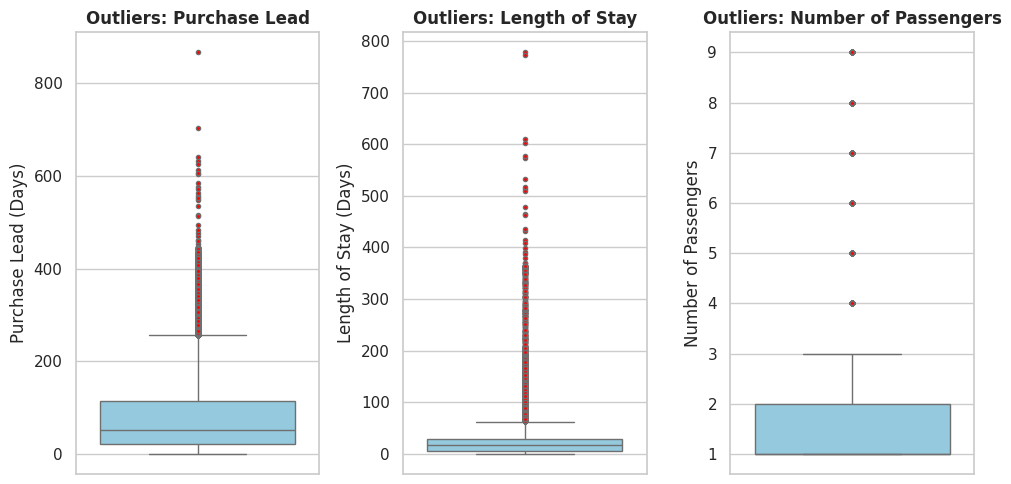

In [16]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(10, 5))

# PURCHASE LEAD
sns.boxplot(
    data=df,
    y='purchase_lead',
    ax=axes[0],
    color='skyblue',
    flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'red'},
)
axes[0].set_title(
    'Outliers: Purchase Lead', fontsize=12, fontweight='bold'
)
axes[0].set_ylabel('Purchase Lead (Days)')

# LENGTH OF STAY
sns.boxplot(
    data=df,
    y='length_of_stay',
    ax=axes[1],
    color='skyblue',
    flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'red'},
)
axes[1].set_title(
    'Outliers: Length of Stay', fontsize=12, fontweight='bold'
)
axes[1].set_ylabel('Length of Stay (Days)')

# NUMBER OF PASSENGERS
sns.boxplot(
    data=df,
    y='num_passengers',
    ax=axes[2],
    color='skyblue',
    flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'red'},
)
axes[2].set_title(
    'Outliers: Number of Passengers', fontsize=12, fontweight='bold'
)
axes[2].set_ylabel('Number of Passengers')

plt.tight_layout()
plt.show()

# Exploratory Data Analysis

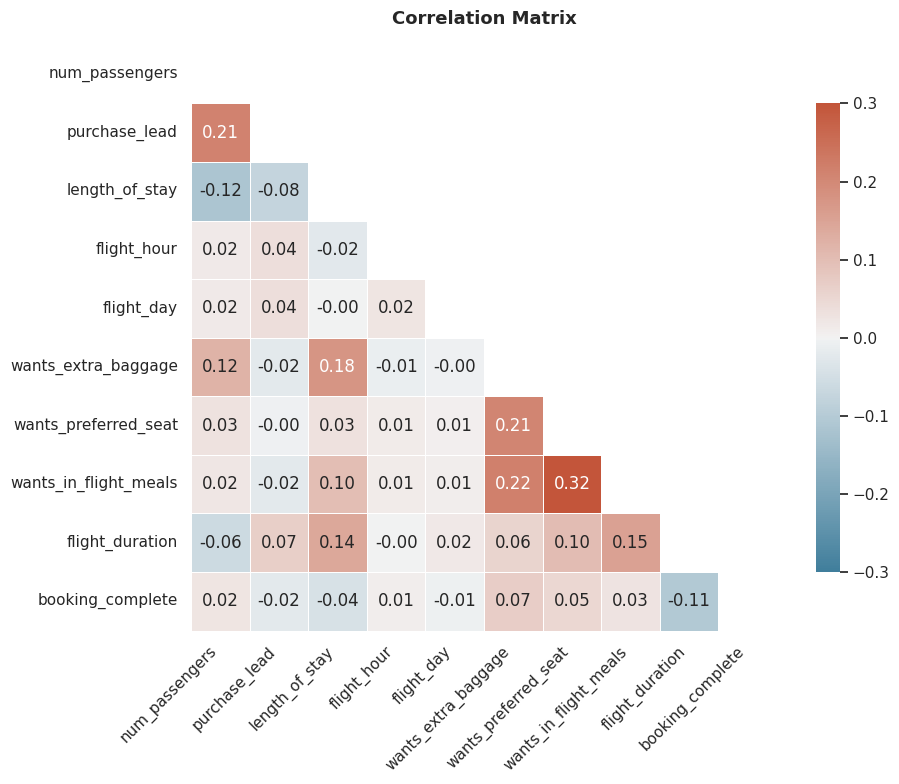

In [20]:
sns.set_theme(style="white")
corr = df.select_dtypes(include=[np.number]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))


sns.heatmap(
    corr,
    mask=mask,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
    vmax=0.3,
    vmin=-0.3,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)

plt.title(
    "Correlation Matrix",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1225/2593358085.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="booking_complete", ax=axes[0, 0], palette="Blues_r")
/tmp/ipykernel_1225/2593358085.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(["No", "Yes"])
/tmp/ipykernel_1225/2593358085.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="sales_channel", ax=axes[1, 0], palette="Blues_r")
/tmp/ipykernel_1225/2593358085.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend

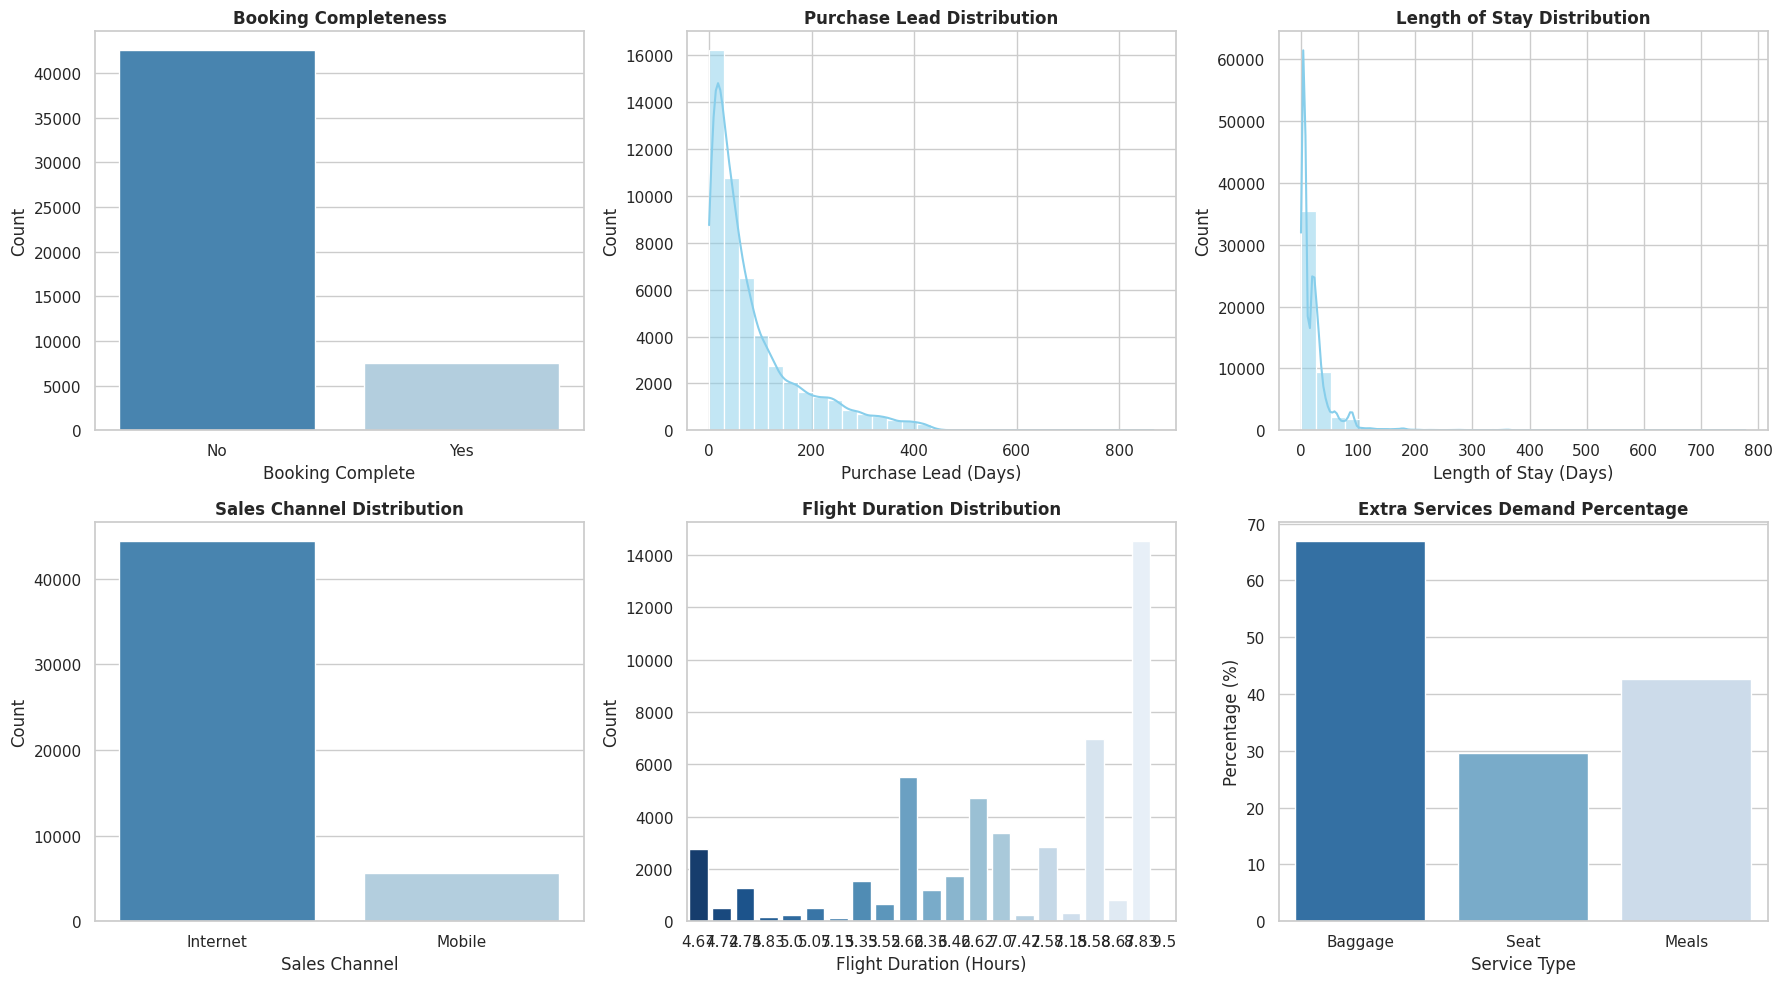

In [19]:
# UNIVARIATE ANALYSIS

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Booking Completeness
sns.countplot(data=df, x="booking_complete", ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Booking Completeness", fontweight="bold")
axes[0, 0].set_xticklabels(["No", "Yes"])
axes[0, 0].set_xlabel("Booking Complete")
axes[0, 0].set_ylabel("Count")

# Purchase Lead Distribution
sns.histplot(df["purchase_lead"], ax=axes[0, 1], color="skyblue", kde=True, bins=30)
axes[0, 1].set_title("Purchase Lead Distribution", fontweight="bold")
axes[0, 1].set_xlabel("Purchase Lead (Days)")
axes[0, 1].set_ylabel("Count")

# Length of Stay Distribution
sns.histplot(df["length_of_stay"], ax=axes[0, 2], color="skyblue", kde=True, bins=30)
axes[0, 2].set_title("Length of Stay Distribution", fontweight="bold")
axes[0, 2].set_xlabel("Length of Stay (Days)")
axes[0, 2].set_ylabel("Count")

# Sales Channel Distribution
sns.countplot(data=df, x="sales_channel", ax=axes[1, 0], palette="Blues_r")
axes[1, 0].set_title("Sales Channel Distribution", fontweight="bold")
axes[1, 0].set_xlabel("Sales Channel")
axes[1, 0].set_ylabel("Count")

# Flight Duration Distribution
sns.countplot(data=df, x="flight_duration", ax=axes[1, 1], palette="Blues_r")
axes[1, 1].set_title("Flight Duration Distribution", fontweight="bold")
axes[1, 1].set_xlabel("Flight Duration (Hours)")
axes[1, 1].set_ylabel("Count")

# Extra Services Demand
extra_counts = {
    "Baggage": df["wants_extra_baggage"].mean() * 100,
    "Seat": df["wants_preferred_seat"].mean() * 100,
    "Meals": df["wants_in_flight_meals"].mean() * 100,
}
sns.barplot(
    x=list(extra_counts.keys()),
    y=list(extra_counts.values()),
    ax=axes[1, 2],
    palette="Blues_r",
)
axes[1, 2].set_title(
    "Extra Services Demand Percentage", fontweight="bold"
)
axes[1, 2].set_xlabel("Service Type")
axes[1, 2].set_ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1225/2130584925.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1225/2130584925.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['No', 'Yes'])
/tmp/ipykernel_1225/2130584925.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1225/2130584925.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['No', 'Yes'])
/tmp/ipykernel_1225/2130584925.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecate

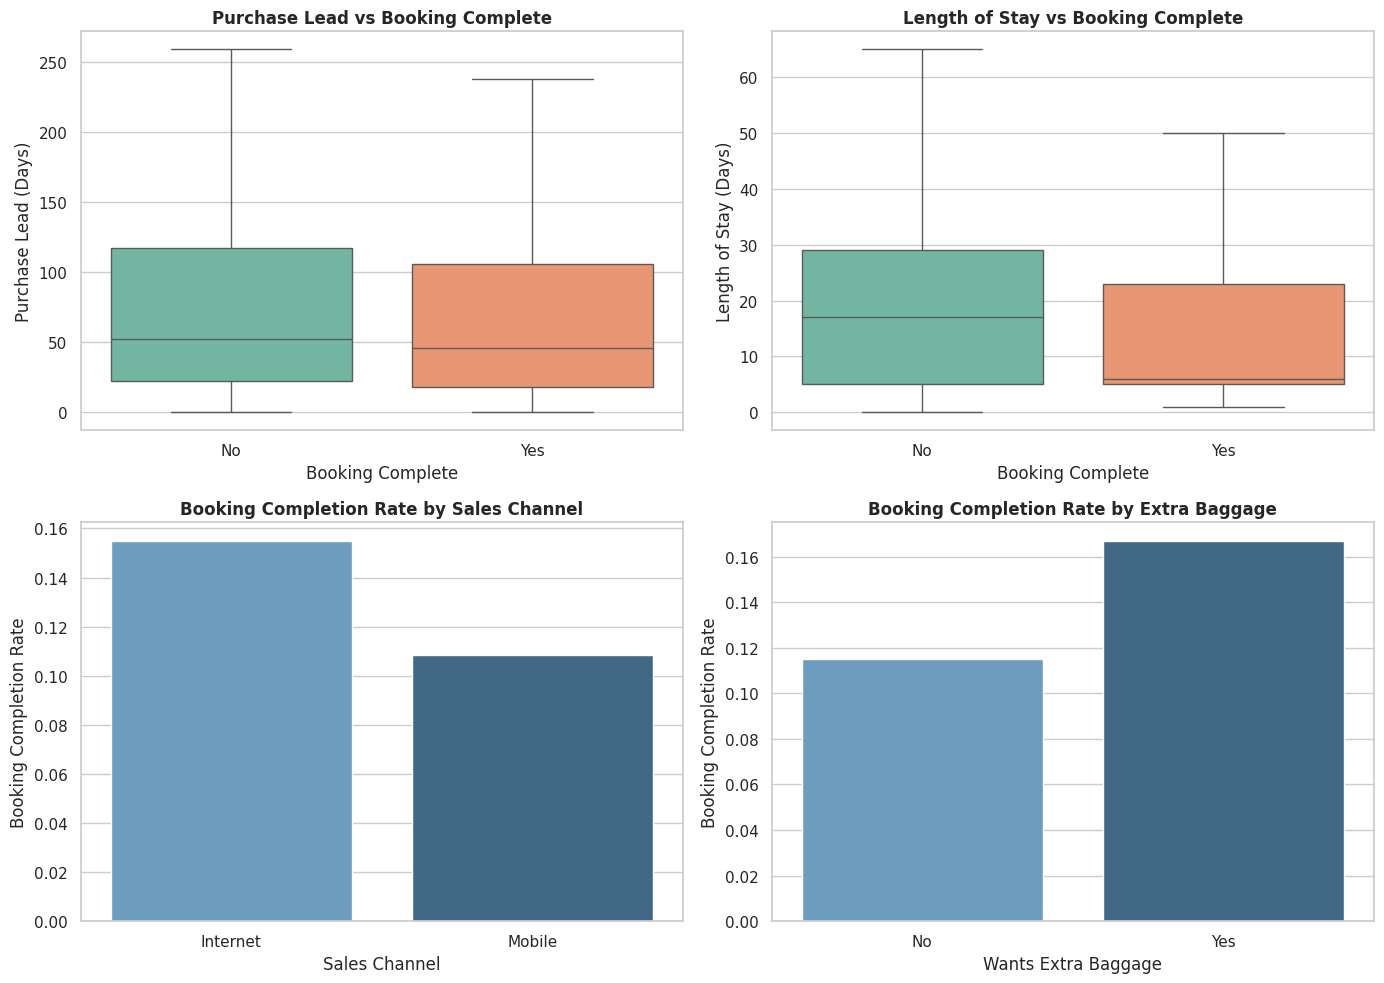

In [22]:
# BIVARIATE ANALYSIS

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Purchase Lead vs Booking Completion
sns.boxplot(
    data=df,
    x='booking_complete',
    y='purchase_lead',
    ax=axes[0, 0],
    palette='Set2',
    showfliers=False,
)
axes[0, 0].set_title(
    'Purchase Lead vs Booking Complete', fontweight='bold'
)
axes[0, 0].set_xticklabels(['No', 'Yes'])
axes[0, 0].set_xlabel('Booking Complete')
axes[0, 0].set_ylabel('Purchase Lead (Days)')
axes[0, 0].tick_params(axis='x', rotation=0)

# Length of Stay vs Booking Completion
sns.boxplot(
    data=df,
    x='booking_complete',
    y='length_of_stay',
    ax=axes[0, 1],
    palette='Set2',
    showfliers=False,
)
axes[0, 1].set_title(
    'Length of Stay vs Booking Complete', fontweight='bold'
)
axes[0, 1].set_xticklabels(['No', 'Yes'])
axes[0, 1].set_xlabel('Booking Complete')
axes[0, 1].set_ylabel('Length of Stay (Days)')
axes[0, 1].tick_params(axis='x', rotation=0)

# Booking Completion Rate by Sales Channel
sns.barplot(
    data=df,
    x='sales_channel',
    y='booking_complete',
    ax=axes[1, 0],
    palette='Blues_d',
    errorbar=None,
)
axes[1, 0].set_title(
    'Booking Completion Rate by Sales Channel', fontweight='bold'
)
axes[1, 0].set_xlabel('Sales Channel')
axes[1, 0].set_ylabel('Booking Completion Rate')
axes[1, 0].tick_params(axis='x', rotation=0)

# Booking Completion Rate by Extra Baggage Preference
sns.barplot(
    data=df,
    x='wants_extra_baggage',
    y='booking_complete',
    ax=axes[1, 1],
    palette='Blues_d',
    errorbar=None,
)
axes[1, 1].set_title(
    'Booking Completion Rate by Extra Baggage', fontweight='bold'
)
axes[1, 1].set_xticklabels(['No', 'Yes'])
axes[1, 1].set_xlabel('Wants Extra Baggage')
axes[1, 1].set_ylabel('Booking Completion Rate')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Feature Engineering

In [23]:
categorical_cols = ['sales_channel', 'trip_type', 'route', 'booking_origin']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['booking_complete'])
y = df_encoded['booking_complete']

X.shape

(50000, 913)

In [26]:
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

In [27]:
df_fe = df.copy()
df_fe['lead_per_stay'] = df_fe['purchase_lead'] / (
    df_fe['length_of_stay'] + 1
)
df_fe['total_ancillary'] = (
    df_fe['wants_extra_baggage']
    + df_fe['wants_preferred_seat']
    + df_fe['wants_in_flight_meals']
)
df_fe['is_weekend'] = df_fe['flight_day'].isin([6, 7]).astype(int)

categorical_cols = ['sales_channel', 'trip_type', 'route', 'booking_origin']
df_encoded = pd.get_dummies(df_fe, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['booking_complete'])
y = df_encoded['booking_complete']

# LIGHT GBM
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=5.6,
    random_state=42,
    n_jobs=-1,
)

auc_scores = []
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
  X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
  y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

  lgbm_model.fit(X_train, y_train)
  y_proba = lgbm_model.predict_proba(X_test)[:, 1]
  auc = roc_auc_score(y_test, y_proba)
  auc_scores.append(auc)
  print(f'Fold {fold} LightGBM ROC-AUC: {auc:.4f}')

print(f'\nAverage ROC-AUC Score: {np.mean(auc_scores):.4f}')

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 5983, number of negative: 34017
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004438 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1614
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 399
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.149575 -> initscore=-1.737938
[LightGBM] [Info] Start training from score -1.737938
Fold 1 LightGBM ROC-AUC: 0.7881
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 5983, number of negative: 34017
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004192 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is n

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 7478, number of negative: 42522
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102144 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1693
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 438
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.149560 -> initscore=-1.738056
[LightGBM] [Info] Start training from score -1.738056


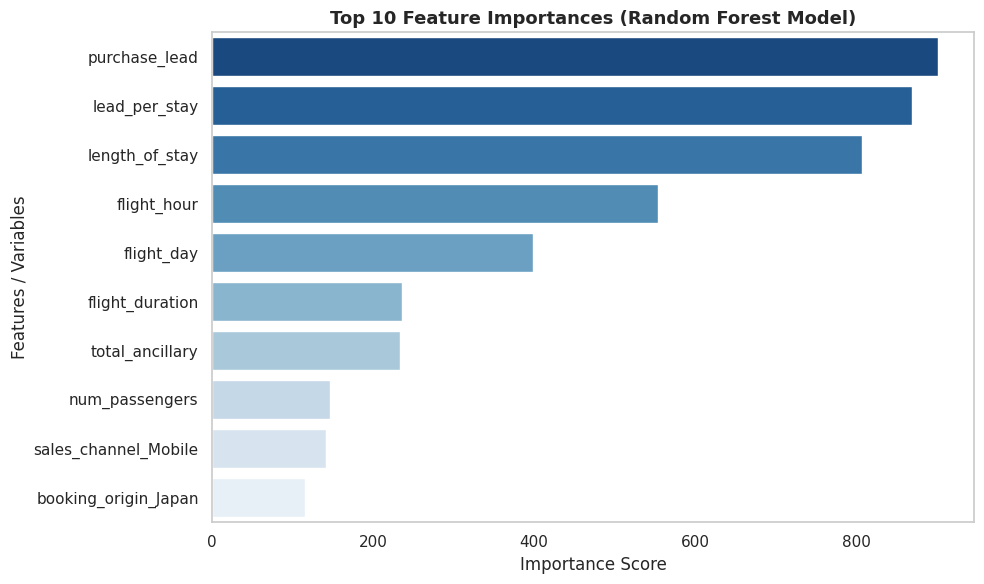

In [29]:
lgbm_model.fit(X, y)

importances = pd.Series(
    lgbm_model.feature_importances_, index=X.columns
).sort_values(ascending=False)
top_10_features = importances.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_10_features.values,
    y=top_10_features.index,
    palette='Blues_r',
    hue=top_10_features.index,
    legend=False,
)

plt.title(
    'Top 10 Feature Importances (Random Forest Model)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Importance Score')
plt.ylabel('Features / Variables')
plt.grid(False)
plt.tight_layout()
plt.show()